# Tahap 5 - Training Model Baseline

## Baseline

In [ ]:
!pip -q install scikit-image joblib

In [ ]:
#@title Import Library
import os
import json
import time
import joblib
import warnings

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image, ImageFile

from skimage.feature import graycomatrix, graycoprops
from skimage.color import rgb2gray
from skimage.transform import resize

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

warnings.filterwarnings("ignore")
ImageFile.LOAD_TRUNCATED_IMAGES = False

sns.set_theme(style="whitegrid")

print("Library berhasil dimuat.")

Library berhasil dimuat.


In [ ]:
#@title Prepare Environtment Baseline
DATASET_DIR = Path("/content/oil_palm_dataset")

SPLITS = ["train", "valid", "test"]

CLASS_COLUMNS = [
    "overripe",
    "ripe",
    "underripe",
    "unripe"
]

RANDOM_STATE = 42

# Konfigurasi ekstraksi fitur
IMAGE_SIZE = (128, 128)

HSV_BINS = {
    "h": 16,
    "s": 8,
    "v": 8
}

GLCM_DISTANCES = [1, 2]
GLCM_ANGLES = [
    0,
    np.pi / 4,
    np.pi / 2,
    3 * np.pi / 4
]

GLCM_LEVELS = 16

# Direktori penyimpanan hasil
OUTPUT_DIR = Path("/content/model_baseline_svm")
FEATURE_DIR = OUTPUT_DIR / "features"
MODEL_DIR = OUTPUT_DIR / "models"
RESULT_DIR = OUTPUT_DIR / "results"

for folder in [FEATURE_DIR, MODEL_DIR, RESULT_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Konfigurasi berhasil.")
print("Dataset:", DATASET_DIR)
print("Output:", OUTPUT_DIR)

Konfigurasi berhasil.
Dataset: /content/oil_palm_dataset
Output: /content/model_baseline_svm


In [ ]:
#@title Memuat dan memvalidasi dataset
dataframes = []

for split in SPLITS:
    annotation_path = DATASET_DIR / split / "_classes.csv"

    if not annotation_path.exists():
        raise FileNotFoundError(
            f"File anotasi tidak ditemukan: {annotation_path}"
        )

    temp_df = pd.read_csv(annotation_path)
    temp_df["split"] = split

    temp_df["image_path"] = temp_df["filename"].apply(
        lambda filename: str(DATASET_DIR / split / filename)
    )

    dataframes.append(temp_df)

df_raw = pd.concat(dataframes, ignore_index=True)

print("Total anotasi awal:", len(df_raw))
display(df_raw.head())

Total anotasi awal: 6412


,filename,overripe,ripe,underripe,unripe,split,image_path
0,overripe-331-_jpg.rf.c1763e711e9ef04733e50d111...,1,0,0,0,train,/content/oil_palm_dataset/train/overripe-331-_...
1,ripe-142-_jpg.rf.08f25705cee08800d054de12cc10b...,0,1,0,0,train,/content/oil_palm_dataset/train/ripe-142-_jpg....
2,ripe-320-_jpg.rf.128360b737a545d72dcf2756f5415...,0,1,0,0,train,/content/oil_palm_dataset/train/ripe-320-_jpg....
3,underripe-166-_png.rf.11d7ca27b9d442bf1a518e05...,0,0,1,0,train,/content/oil_palm_dataset/train/underripe-166-...
4,underripe-650-_jpg.rf.f0094e57fc4e11bf3b8822ac...,0,0,0,0,train,/content/oil_palm_dataset/train/underripe-650-...


In [ ]:
#@title cek keberadaan & validasi gambar
for col in CLASS_COLUMNS:
    df_raw[col] = pd.to_numeric(df_raw[col], errors="coerce")

label_values = df_raw[CLASS_COLUMNS]

is_binary = label_values.isin([0, 1]).all(axis=1)
one_hot_sum = label_values.sum(axis=1)

df_raw["valid_label"] = (
    is_binary &
    one_hot_sum.eq(1)
)

df_raw["image_exists"] = df_raw["image_path"].apply(
    lambda path: Path(path).is_file()
)

df_valid = df_raw[
    df_raw["valid_label"] &
    df_raw["image_exists"]
].copy()

df_valid["label"] = (
    df_valid[CLASS_COLUMNS]
    .idxmax(axis=1)
)

print("Total anotasi:", len(df_raw))
print("Label valid:", df_valid.shape[0])
print("Label tidak valid:", (~df_raw["valid_label"]).sum())
print("Gambar tidak ditemukan:", (~df_raw["image_exists"]).sum())

print("\nDistribusi data berdasarkan split:")
display(
    df_valid.groupby("split")["filename"]
    .count()
    .rename("jumlah")
    .to_frame()
)

Total anotasi: 6412
Label valid: 5790
Label tidak valid: 622
Gambar tidak ditemukan: 0

Distribusi data berdasarkan split:


,jumlah
split,
test,242
train,5074
valid,474


In [ ]:
#@title cek apakah gambar bisa di buka
def check_image_readable(image_path):
    try:
        with Image.open(image_path) as img:
            img.verify()
        return True
    except Exception:
        return False


df_valid["image_readable"] = df_valid["image_path"].apply(
    check_image_readable
)

df_clean = df_valid[
    df_valid["image_readable"]
].copy()

print("Total data siap digunakan:", len(df_clean))

display(
    df_clean.groupby(["split", "label"])
    .size()
    .unstack(fill_value=0)
)

Total data siap digunakan: 5790


label,overripe,ripe,underripe,unripe
split,,,,
test,78,61,55,48
train,1392,1431,1237,1014
valid,136,128,118,92


In [ ]:
#@title ektrak fitur warna hsv
def extract_hsv_features(image_path):
    with Image.open(image_path) as img:
        img = img.convert("RGB")
        img = img.resize(IMAGE_SIZE)

        hsv_image = np.array(img.convert("HSV"))

    features = []

    channel_configs = [
        (0, HSV_BINS["h"]),
        (1, HSV_BINS["s"]),
        (2, HSV_BINS["v"])
    ]

    for channel, bins in channel_configs:
        histogram, _ = np.histogram(
            hsv_image[:, :, channel],
            bins=bins,
            range=(0, 256)
        )

        histogram = histogram.astype("float32")
        histogram /= histogram.sum() + 1e-8

        features.extend(histogram)

    return np.array(features, dtype=np.float32)


hsv_sample = extract_hsv_features(
    df_clean.iloc[0]["image_path"]
)

print("Jumlah fitur HSV:", len(hsv_sample))
print("Contoh fitur:", hsv_sample[:10])

Jumlah fitur HSV: 32
Contoh fitur: [0.7381592  0.0949707  0.0345459  0.01989746 0.00567627 0.00921631
 0.00738525 0.00799561 0.00488281 0.00848389]


In [ ]:
#@title extrak fitur tekstur GLCM
GLCM_PROPERTIES = [
    "contrast",
    "dissimilarity",
    "homogeneity",
    "energy",
    "correlation",
    "ASM"
]


def extract_glcm_features(image_path):
    with Image.open(image_path) as img:
        img = img.convert("RGB")
        img = img.resize(IMAGE_SIZE)

        rgb_image = np.array(img)

    gray_image = rgb2gray(rgb_image)

    # Kuantisasi grayscale menjadi 16 level
    gray_quantized = (
        gray_image * (GLCM_LEVELS - 1)
    ).astype(np.uint8)

    glcm = graycomatrix(
        gray_quantized,
        distances=GLCM_DISTANCES,
        angles=GLCM_ANGLES,
        levels=GLCM_LEVELS,
        symmetric=True,
        normed=True
    )

    features = []

    for prop in GLCM_PROPERTIES:
        values = graycoprops(glcm, prop)
        features.extend(values.flatten())

    return np.array(features, dtype=np.float32)


glcm_sample = extract_glcm_features(
    df_clean.iloc[0]["image_path"]
)

print("Jumlah fitur GLCM:", len(glcm_sample))
print("Contoh fitur:", glcm_sample[:10])

Jumlah fitur GLCM: 48
Contoh fitur: [3.1078987 5.025358  3.7914617 4.982702  5.296627  5.025358  7.0562997
 4.982702  1.019685  1.3289107]


In [ ]:
#@title Extrack semua fitur
from tqdm.auto import tqdm


def extract_all_features(image_path):
    hsv_features = extract_hsv_features(image_path)
    glcm_features = extract_glcm_features(image_path)

    return np.concatenate([
        hsv_features,
        glcm_features
    ])


feature_names = []

# Nama fitur HSV
for channel, bins in HSV_BINS.items():
    for i in range(bins):
        feature_names.append(f"hsv_{channel}_{i}")

# Nama fitur GLCM
for prop in GLCM_PROPERTIES:
    for distance in GLCM_DISTANCES:
        for angle_idx in range(len(GLCM_ANGLES)):
            feature_names.append(
                f"glcm_{prop}_d{distance}_a{angle_idx}"
            )

assert len(feature_names) == 80

X_all = []
metadata = []

start_time = time.time()

for row in tqdm(
    df_clean.itertuples(index=False),
    total=len(df_clean),
    desc="Ekstraksi fitur"
):
    features = extract_all_features(row.image_path)

    X_all.append(features)

    metadata.append({
        "filename": row.filename,
        "split": row.split,
        "label": row.label,
        "image_path": row.image_path
    })

X_all = np.array(X_all, dtype=np.float32)
df_metadata = pd.DataFrame(metadata)

print("Ekstraksi selesai.")
print("Shape feature matrix:", X_all.shape)
print("Jumlah fitur:", len(feature_names))
print("Waktu ekstraksi:", round(time.time() - start_time, 2), "detik")

Ekstraksi fitur:   0%|          | 0/5790 [00:00<?, ?it/s]

Ekstraksi selesai.
Shape feature matrix: (5790, 80)
Jumlah fitur: 80
Waktu ekstraksi: 145.07 detik


In [ ]:
#@title Simpan hasil semua ekstraksi
df_features = pd.DataFrame(
    X_all,
    columns=feature_names
)

df_features = pd.concat(
    [
        df_metadata.reset_index(drop=True),
        df_features.reset_index(drop=True)
    ],
    axis=1
)

feature_path = FEATURE_DIR / "svm_features.csv"

df_features.to_csv(feature_path, index=False)

print("Fitur berhasil disimpan:", feature_path)

Fitur berhasil disimpan: /content/model_baseline_svm/features/svm_features.csv


In [ ]:
#@title Menyiapkan training, validation, dan test
train_mask = df_features["split"].eq("train")
valid_mask = df_features["split"].eq("valid")
test_mask = df_features["split"].eq("test")

X_train = df_features.loc[train_mask, feature_names].values
y_train = df_features.loc[train_mask, "label"].values

X_valid = df_features.loc[valid_mask, feature_names].values
y_valid = df_features.loc[valid_mask, "label"].values

X_test = df_features.loc[test_mask, feature_names].values
y_test = df_features.loc[test_mask, "label"].values

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_valid.shape, y_valid.shape)
print("Testing:", X_test.shape, y_test.shape)

Training: (5074, 80) (5074,)
Validation: (474, 80) (474,)
Testing: (242, 80) (242,)


In [ ]:
#@title Memastikan tidak ada NaN atau infinity
assert np.isfinite(X_train).all()
assert np.isfinite(X_valid).all()
assert np.isfinite(X_test).all()

assert set(y_train).issubset(CLASS_COLUMNS)
assert set(y_valid).issubset(CLASS_COLUMNS)
assert set(y_test).issubset(CLASS_COLUMNS)

print("Pemeriksaan fitur berhasil.")

Pemeriksaan fitur berhasil.


In [ ]:
#@title Menyiapkan Model SVM
model_svm = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale",
        class_weight="balanced",
        random_state=RANDOM_STATE
    ))
])

print("Model SVM berhasil dibuat.")

Model SVM berhasil dibuat.


In [ ]:
#@title Training SVM
start_time = time.time()

model_svm.fit(X_train, y_train)

training_time = time.time() - start_time

print("Training SVM selesai.")
print("Waktu training:", round(training_time, 2), "detik")

Training SVM selesai.
Waktu training: 2.3 detik


In [ ]:
#@title Evaluasi SVM
y_valid_pred = model_svm.predict(X_valid)

accuracy = accuracy_score(y_valid, y_valid_pred)

precision_macro = precision_score(
    y_valid,
    y_valid_pred,
    average="macro",
    zero_division=0
)

recall_macro = recall_score(
    y_valid,
    y_valid_pred,
    average="macro",
    zero_division=0
)

f1_macro = f1_score(
    y_valid,
    y_valid_pred,
    average="macro",
    zero_division=0
)

f1_weighted = f1_score(
    y_valid,
    y_valid_pred,
    average="weighted",
    zero_division=0
)

results_svm = {
    "model": "SVM RBF",
    "accuracy": accuracy,
    "precision_macro": precision_macro,
    "recall_macro": recall_macro,
    "f1_macro": f1_macro,
    "f1_weighted": f1_weighted,
    "training_time_seconds": training_time
}

display(
    pd.DataFrame([results_svm])
    .round(4)
)

print(
    classification_report(
        y_valid,
        y_valid_pred,
        labels=CLASS_COLUMNS,
        target_names=CLASS_COLUMNS,
        zero_division=0
    )
)

,model,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,training_time_seconds
0,SVM RBF,0.7595,0.7652,0.7644,0.7639,0.7602,2.2967


              precision    recall  f1-score   support

    overripe       0.79      0.71      0.75       136
        ripe       0.66      0.73      0.69       128
   underripe       0.82      0.81      0.82       118
      unripe       0.79      0.80      0.80        92

    accuracy                           0.76       474
   macro avg       0.77      0.76      0.76       474
weighted avg       0.76      0.76      0.76       474



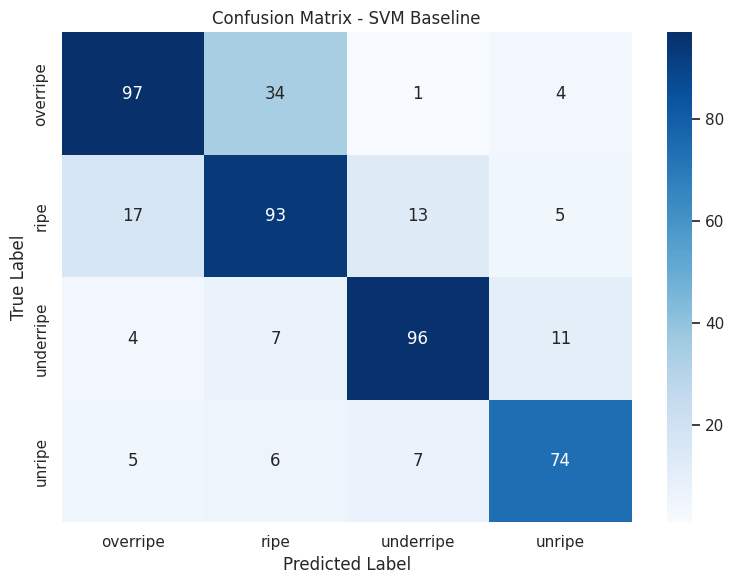

In [ ]:
#@title Visualisasi Confusion Matrix SVM
cm = confusion_matrix(
    y_valid,
    y_valid_pred,
    labels=CLASS_COLUMNS
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_COLUMNS,
    yticklabels=CLASS_COLUMNS
)

plt.title("Confusion Matrix - SVM Baseline")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

In [ ]:
#@title Menyimpan model dan hasil eksperimen
# Simpan model dan scaler dalam satu pipeline
joblib.dump(
    model_svm,
    MODEL_DIR / "svm_baseline_pipeline.joblib"
)

# Simpan daftar fitur
with open(
    MODEL_DIR / "feature_names.json",
    "w"
) as file:
    json.dump(feature_names, file, indent=4)

# Simpan hasil evaluasi
with open(
    RESULT_DIR / "validation_metrics.json",
    "w"
) as file:
    json.dump(results_svm, file, indent=4)

# Simpan prediksi validation
df_validation_result = pd.DataFrame({
    "filename": df_features.loc[valid_mask, "filename"].values,
    "actual_label": y_valid,
    "predicted_label": y_valid_pred
})

df_validation_result.to_csv(
    RESULT_DIR / "validation_predictions.csv",
    index=False
)

print("Seluruh artefak baseline SVM berhasil disimpan.")

Seluruh artefak baseline SVM berhasil disimpan.
